# Monte Carlo and Quasi-Monte Carlo Parameter Sweeps

:::{tip} Run interactively
Run this notebook interactively in your browser with zero installation:
- **[Open in JupyterLite Lab](/lite/lab/index.html?path=user-guide/sweep/mc-sampling.ipynb)**
:::

Cartesian grids scale exponentially ($N^D$) and quickly become impractical once you vary three or more parameters. By default (`grid=False`), `sweep()` pairs all parameter arrays **elementwise** (lockstep zip), so any Monte Carlo or quasi-Monte Carlo (QMC) sample matrix can be passed directly into a single sweep call.

This notebook demonstrates:
1. Comparing uniform random, **Latin Hypercube (LHS)**, and **Sobol** space-filling designs in 3D (`scipy.stats.qmc`).
2. Running a 3D Sobol sweep on a heterogeneous hybrid network (`MontbrioPazoRoxin` + `SupHopf`).
3. Controlling stochastic variance in `HeunStochastic` sweeps with **common random numbers** (`shared_noise=True`) vs. independent replicates (`noise_seeds`).
4. Collecting compact parameter–feature tables with zero trajectory memory via `monitor="features"`.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import scipy.sparse as sp
from scipy.stats import qmc, spearmanr
import matplotlib.pyplot as plt

from tvb.simulator.hybrid import Subnetwork, IntraProjection, InterProjection, NetworkSet
from tvb.simulator.hybrid.coupling import Linear
from tvb.simulator.models import MontbrioPazoRoxin, SupHopf
from tvb.simulator.integrators import HeunDeterministic, HeunStochastic, noise
from tvb.simulator.backend.cpp_hybrid import notebook as nb
from tvb.simulator.backend.cpp_hybrid.backend import CppHybridBackend

## 1. Space-filling designs: Uniform random vs. LHS vs. Sobol

We generate $N = 64$ points in $[0, 1]^3$ using pseudo-random uniform draws, Latin Hypercube Sampling (`qmc.LatinHypercube`), and a scrambled Sobol sequence (`qmc.Sobol`), and compare their 2D marginal projections. Low-discrepancy Sobol points avoid both gaps and accidental clusters.

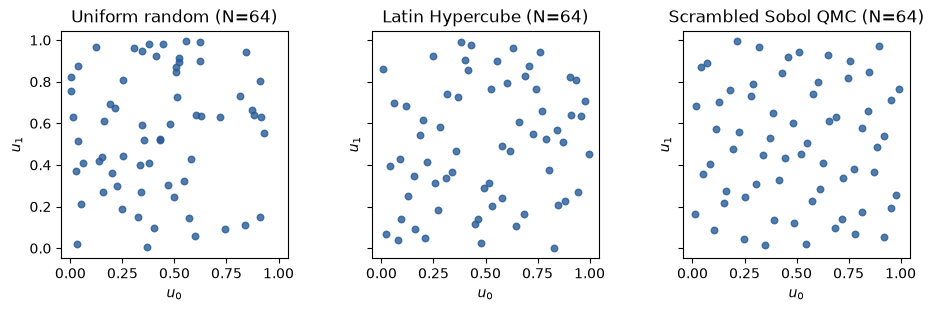

In [2]:
N_SAMPLES = 64
rng = np.random.default_rng(7)
u_rand = rng.random((N_SAMPLES, 3))
u_lhs = qmc.LatinHypercube(d=3, seed=7).random(N_SAMPLES)
u_sobol = qmc.Sobol(d=3, scramble=True, seed=7).random_base2(m=6)  # 2^6 = 64

fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.0), sharex=True, sharey=True, layout="constrained")
for ax, pts, title in [
    (axes[0], u_rand, "Uniform random (N=64)"),
    (axes[1], u_lhs, "Latin Hypercube (N=64)"),
    (axes[2], u_sobol, "Scrambled Sobol QMC (N=64)"),
]:
    ax.scatter(pts[:, 0], pts[:, 1], s=22, alpha=0.8, color="#275b97")
    ax.set(title=title, xlabel="$u_0$", ylabel="$u_1$")
    ax.set_aspect("equal")
plt.show()

## 2. Running a 3D Sobol sweep on a heterogeneous hybrid network

We map the unit-cube Sobol coordinates onto three parameters of a coupled `MontbrioPazoRoxin` (`cortex`) $\to$ `SupHopf` (`subcortex`) network:
- `cortex.eta` $\in [-6.0, -2.5]$
- `subcortex.a` $\in [-0.4, 0.3]$
- `coupling_scale` $\in [0.05, 0.8]$

Because `grid=False` is the default, `nb.sweep` evaluates the exact 64 paired 3D points in one call.

In [3]:
dt = 0.1
c0 = np.array([0], dtype=np.int_)

def build_hybrid_mc(stochastic=False):
    m_c = MontbrioPazoRoxin(J=np.array([15.0]), Delta=np.array([1.0]))
    m_c.configure()
    m_s = SupHopf(a=np.array([-0.1]), omega=np.array([2 * np.pi * 0.01]))
    m_s.configure()
    if stochastic:
        sc_c = HeunStochastic(dt=dt, noise=noise.Additive(nsig=np.array([2e-3]), noise_seed=11))
        sc_s = HeunStochastic(dt=dt, noise=noise.Additive(nsig=np.array([2e-3]), noise_seed=22))
    else:
        sc_c = HeunDeterministic(dt=dt)
        sc_s = HeunDeterministic(dt=dt)
    sn_c = Subnetwork(name="cortex", model=m_c, scheme=sc_c, nnodes=6)
    w_c = sp.csr_matrix(np.full((6, 6), 0.02, dtype=np.float32) * (1 - np.eye(6, dtype=np.float32)))
    sn_c.projections = [
        IntraProjection(
            source_cvar=c0, target_cvar=c0, weights=w_c,
            lengths=sp.csr_matrix((6, 6), dtype=np.float32),
            cv=5.0, dt=dt, scale=0.1, cfun=Linear(),
        )
    ]
    sn_c.configure()
    sn_s = Subnetwork(name="subcortex", model=m_s, scheme=sc_s, nnodes=4).configure()
    w_cs = sp.csr_matrix(np.full((4, 6), 0.05, dtype=np.float32))
    proj = InterProjection(
        source=sn_c, target=sn_s, source_cvar=c0, target_cvar=c0,
        weights=w_cs, lengths=sp.csr_matrix((4, 6), dtype=np.float32),
        cv=5.0, dt=dt, scale=0.2, cfun=Linear(),
    )
    return NetworkSet(subnets=[sn_c, sn_s], projections=[proj]).configure()

ns_det = build_hybrid_mc(stochastic=False)
bounds_lo = np.array([-6.0, -0.4, 0.05])
bounds_hi = np.array([-2.5, 0.3, 0.8])
X_sobol = qmc.scale(u_sobol, bounds_lo, bounds_hi).astype(np.float32)

ic_mc = [
    np.array([np.full((6, 1), 0.1), np.full((6, 1), -1.5)]),
    np.zeros((2, 4, 1)),
]
res_sobol = nb.sweep(
    ns_det,
    nstep=1000,
    initial_states=ic_mc,
    **{
        "cortex.eta": X_sobol[:, 0],
        "subcortex.a": X_sobol[:, 1],
        "coupling_scale": X_sobol[:, 2],
    },
)
sub_rms = np.sqrt(np.mean(res_sobol.squeezed("subcortex")[:, 400:, 0, :] ** 2, axis=(1, 2)))
assert np.isfinite(sub_rms).all()
print(f"64-point 3D Sobol sweep finished in {res_sobol.elapsed*1e3:.1f} ms")

64-point 3D Sobol sweep finished in 32.7 ms


## 3. Stochastic sweeps: common random numbers (`shared_noise=True`) vs. `noise_seeds`

In stochastic {term}`SDE <Stochastic differential equation>` sweeps, `CppHybridBackend().sweep` controls how noise streams are assigned across parameter sets:
- **`shared_noise=True`** reuses the exact same noise realization across every parameter row (**common random numbers**), suppressing Monte Carlo jitter when estimating smooth parameter trends or sensitivities.
- **`noise_seeds`** assigns distinct per-row seeds for independent stochastic replicates, letting you measure trial-to-trial ensemble variance.

*(See [C++ Hybrid Backend](../hpc/cpp-hybrid-backend.md) for the underlying counter-based RNG implementation.)*

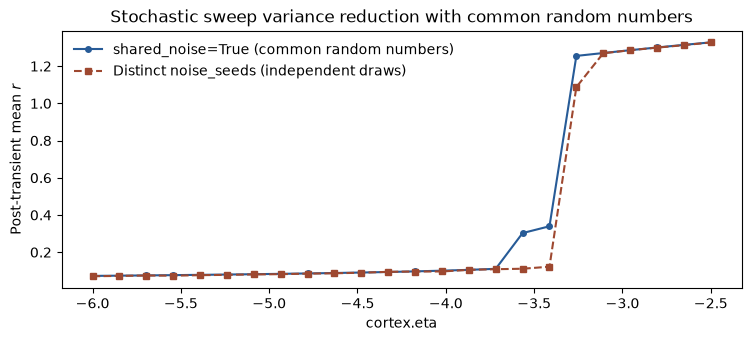

In [4]:
ns_st = build_hybrid_mc(stochastic=True)
cpp = CppHybridBackend()
eta_slice = np.linspace(-6.0, -2.5, 24, dtype=np.float32)

res_shared = cpp.sweep(
    ns_st, {"cortex.eta": eta_slice}, nstep=1000,
    initial_states=ic_mc, shared_noise=True,
)
res_indep = cpp.sweep(
    ns_st, {"cortex.eta": eta_slice}, nstep=1000,
    initial_states=ic_mc,
    noise_seeds=np.arange(100, 124, dtype=np.uint64),
)

ctx_shared = res_shared.squeezed("cortex")[:, 400:, 0, :].mean(axis=(1, 2))
ctx_indep = res_indep.squeezed("cortex")[:, 400:, 0, :].mean(axis=(1, 2))
assert np.isfinite(ctx_shared).all() and np.isfinite(ctx_indep).all()

fig, ax = plt.subplots(figsize=(7.4, 3.3), layout="constrained")
ax.plot(eta_slice, ctx_shared, "o-", ms=4, color="#275b97", label="shared_noise=True (common random numbers)")
ax.plot(eta_slice, ctx_indep, "s--", ms=4, color="#9e4830", label="Distinct noise_seeds (independent draws)")
ax.set(title="Stochastic sweep variance reduction with common random numbers", xlabel="cortex.eta", ylabel="Post-transient mean $r$")
ax.legend(frameon=False)
plt.show()

## 4. Zero-storage online features (`monitor="features"`) for inference tables

For large ensembles (e.g., training a {term}`simulation-based inference` density estimator; see [Inference](../inference.md)), storing full trajectories becomes memory-bound. Passing `monitor="features"` computes any of the **16 single-pass streaming statistics** (`mean`, `var`, `std`, `min`, `max`, `rms`, `abs_energy`, `average_power`, `auc`, `auc_trapz`, `zero_crossing`, `burstiness`, `moments`, `skewness`, `kurtosis`, `centroid`) directly over the neural VOI stream with zero trajectory storage (`res.tavg == {}`).

Remember from [Sweep Theory](theory.md) that online features integrate over the entire run from step 1 on neural variables; if you need burn-in trimming, quantiles/entropy, PSD summaries, or `BalloonWindkessel` BOLD features, record a downsampled monitor stream and pass it to `features.compute_features(...)` in post-processing.

128-point streaming sweep elapsed: 41.7 ms
   cortex.eta  subcortex.a  coupling_scale  sub_mean   sub_std   sub_rms  \
0   -5.061584     0.080017        0.558081  0.004567  0.177172  0.177231   
1   -3.351237    -0.123445        0.213202  0.009810  0.001578  0.009936   
2   -3.552532     0.193227        0.794752  0.024990  0.290361  0.291435   
3   -5.260205    -0.349788        0.345685  0.004398  0.000431  0.004419   
4   -5.857571     0.240662        0.081979  0.000684  0.315159  0.315160   

   sub_zero_crossing  sub_burstiness  
0                2.0        0.949744  
1                0.0       -0.722864  
2                2.0        0.841510  
3                0.0       -0.821500  
4                2.0        0.995671  


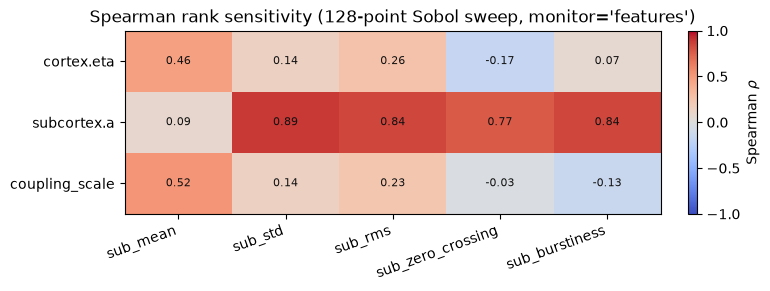

In [5]:
u_128 = qmc.Sobol(d=3, scramble=True, seed=99).random_base2(m=7)  # 128 points
X_128 = qmc.scale(u_128, bounds_lo, bounds_hi).astype(np.float32)
feat_names = ["mean", "std", "rms", "zero_crossing", "burstiness"]

res_feat = nb.sweep(
    ns_det,
    nstep=1200,
    monitor="features",
    features=feat_names,
    initial_states=ic_mc,
    **{
        "cortex.eta": X_128[:, 0],
        "subcortex.a": X_128[:, 1],
        "coupling_scale": X_128[:, 2],
    },
)
assert res_feat.tavg == {}, "monitor='features' allocates zero time-series output"
sub_feats = res_feat.features(feat_names, svar=0, subnet="subcortex")

import pandas as pd
df = pd.DataFrame(res_feat.sweep_values, columns=res_feat.param_keys)
for fname in feat_names:
    df[f"sub_{fname}"] = sub_feats[fname].mean(axis=1)

print(f"128-point streaming sweep elapsed: {res_feat.elapsed*1e3:.1f} ms")
print(df.head())

# Spearman rank sensitivity matrix: parameters (rows) vs features (cols)
pcols = res_feat.param_keys
fcols = [f"sub_{f}" for f in feat_names]
corr = np.array([[spearmanr(df[p], df[f]).statistic for f in fcols] for p in pcols])

fig, ax = plt.subplots(figsize=(7.6, 2.8), layout="constrained")
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
ax.set_xticks(range(len(fcols)), fcols, rotation=20, ha="right")
ax.set_yticks(range(len(pcols)), pcols)
ax.set_title("Spearman rank sensitivity (128-point Sobol sweep, monitor='features')")
for i in range(len(pcols)):
    for j in range(len(fcols)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=8, color="#111")
fig.colorbar(im, ax=ax, label="Spearman $\\rho$")
plt.show()

## Next steps

- [Hybrid Sweep Workflows and Performance](backends.ipynb) — end-to-end excitability-to-PSD and excitability-to-Balloon–Windkessel BOLD FC workflows.
- [Inference](../inference.md) — use simulated parameter–feature tables to train amortised posteriors.